### Testing different p values by changing data points 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import linregress

spring = pd.read_csv("../../data/ratios_VHF_spring.csv")
summer = pd.read_csv("../../data/ratios_VHF_summer.csv")

### Original Linear Regressions

In [2]:
# Strip whitespace from headers so that the column names are consistent.
spring = spring.rename(columns=lambda column: column.strip())
summer = summer.rename(columns=lambda column: column.strip())

grain_size_columns = ["coarse_sand", "fine_sand", "silt", "clay"]
season_data = {"Spring": spring, "Summer": summer}

regression_rows = []
for season, data in season_data.items():
    for grain_size in grain_size_columns:
        valid = data[["VHF", grain_size]].dropna()
        if len(valid) < 3 or valid["VHF"].nunique() < 2:
            regression_rows.append({
                "season": season,
                "grain_size": grain_size,
                "n": len(valid),
                "slope": np.nan,
                "intercept": np.nan,
                "r_squared": np.nan,
                "p_value": np.nan,
            })
            continue

        regression = linregress(valid["VHF"], valid[grain_size])
        regression_rows.append({
            "season": season,
            "grain_size": grain_size,
            "n": len(valid),
            "slope": regression.slope,
            "intercept": regression.intercept,
            "r_squared": regression.rvalue ** 2,
            "p_value": regression.pvalue,
        })

regression_results = pd.DataFrame(regression_rows)
regression_results

,season,grain_size,n,slope,intercept,r_squared,p_value
0,Spring,coarse_sand,7,-1.779493,-0.148915,0.857034,0.002770
1,Spring,fine_sand,7,-1.974403,0.019691,0.543938,0.058508
2,Spring,silt,7,-2.301857,-0.048167,0.551370,0.055915
3,Spring,clay,7,-2.525609,-0.055886,0.550982,0.056048
4,Summer,coarse_sand,5,-1.767383,-0.427664,0.255416,0.385073
5,Summer,fine_sand,5,-1.935042,-0.052390,0.743931,0.059918
6,Summer,silt,5,-0.962597,0.133020,0.404051,0.249070
7,Summer,clay,5,-1.432234,0.014055,0.423289,0.234488


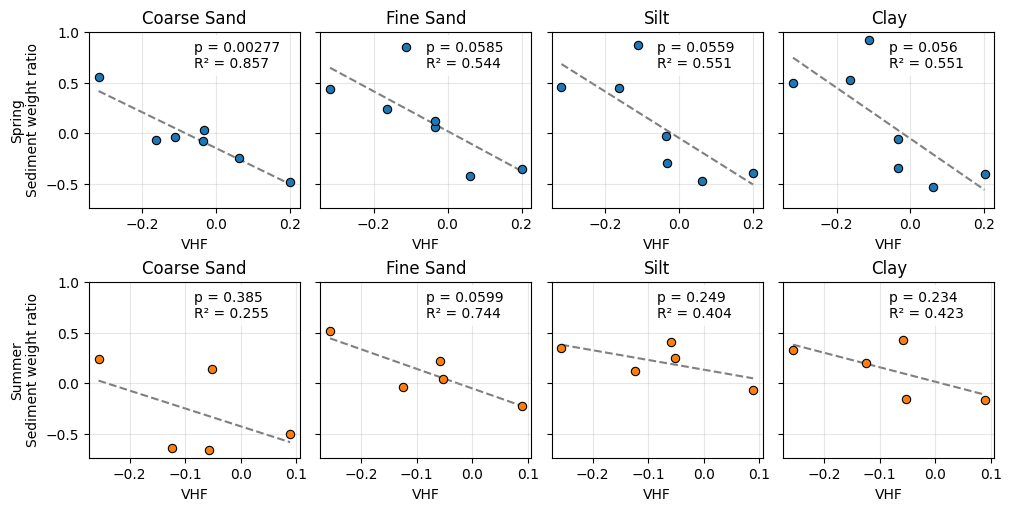

In [3]:
fig, axes = plt.subplots(
    nrows=len(season_data),
    ncols=len(grain_size_columns),
    figsize=(10, 5),
    sharey=True,
    constrained_layout=True,
)

colors = {"Spring": "tab:blue", "Summer": "tab:orange"}
for row, (season, data) in enumerate(season_data.items()):
    for column, grain_size in enumerate(grain_size_columns):
        ax = axes[row, column]
        valid = data[["VHF", grain_size]].dropna()
        result = regression_results[
            (regression_results["season"] == season)
            & (regression_results["grain_size"] == grain_size)
        ].iloc[0]

        ax.scatter(
            valid["VHF"],
            valid[grain_size],
            color=colors[season],
            edgecolor="black",
            linewidth=0.8,
            zorder=2,
        )
        if pd.notna(result["slope"]):
            x_line = np.linspace(valid["VHF"].min(), valid["VHF"].max(), 100)
            ax.plot(
                x_line,
                result["intercept"] + result["slope"] * x_line,
                color="grey",
                linewidth=1.5,
                zorder=1,
                linestyle="--",
            )
            annotation = f"p = {result['p_value']:.3g}\nR² = {result['r_squared']:.3f}"
        else:
            annotation = "Insufficient data"

        ax.text(
            0.5,
            0.95,
            annotation,
            transform=ax.transAxes,
            ha="left",
            va="top",
            bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
        )
        ax.set_title(grain_size.replace("_", " ").title())
        ax.set_xlabel("VHF")
        ax.grid(alpha=0.3)
        if column == 0:
            ax.set_ylabel(f"{season}\nSediment weight ratio")

plt.show()

### Spring 5-Point Iterations by Grain Size

In [4]:
from itertools import combinations

# test every 5-probe subset of the spring observations for each grain-size class
n_observations = 5
spring = spring.rename(columns=lambda column: column.strip())
grain_size_columns = ["coarse_sand", "fine_sand", "silt", "clay"]

iteration_rows = []
for grain_size in grain_size_columns:
    valid = spring[["probe", "VHF", grain_size]].dropna().reset_index(drop=True)
    if len(valid) < n_observations:
        raise ValueError(
            f"{grain_size} has only {len(valid)} valid spring observations; "
            f"{n_observations} are required."
        )

    for iteration, selected_indices in enumerate(
        combinations(valid.index, n_observations),
        start=1,
    ):
        selected = valid.loc[list(selected_indices)]
        regression = linregress(selected["VHF"], selected[grain_size])
        iteration_rows.append({
            "season": "Spring",
            "grain_size": grain_size,
            "iteration": iteration,
            "n": len(selected),
            "retained_probes": tuple(selected["probe"]),
            "slope": regression.slope,
            "intercept": regression.intercept,
            "r_squared": regression.rvalue ** 2,
            "p_value": regression.pvalue,
        })

spring_iteration_results = pd.DataFrame(iteration_rows)
spring_iteration_results.to_csv("spring_iteration_results.csv", index=False)
spring_iteration_results

,season,grain_size,iteration,n,retained_probes,slope,intercept,r_squared,p_value
0,Spring,coarse_sand,1,5,"(T1, T2, T3, T5, T6)",-1.955054,-0.138673,0.963653,0.002974
1,Spring,coarse_sand,2,5,"(T1, T2, T3, T5, T7)",-1.806674,-0.177646,0.886749,0.016761
2,Spring,coarse_sand,3,5,"(T1, T2, T3, T5, T8)",-1.950046,-0.116536,0.949366,0.004911
3,Spring,coarse_sand,4,5,"(T1, T2, T3, T6, T7)",-1.832668,-0.179737,0.878264,0.018732
4,Spring,coarse_sand,5,5,"(T1, T2, T3, T6, T8)",-1.943743,-0.118777,0.944057,0.005713
...,...,...,...,...,...,...,...,...,...
79,Spring,clay,17,5,"(T2, T3, T5, T6, T8)",-2.914442,-0.154589,0.475630,0.197589
80,Spring,clay,18,5,"(T2, T3, T5, T7, T8)",-3.041206,-0.128107,0.485308,0.191182
81,Spring,clay,19,5,"(T2, T3, T6, T7, T8)",-2.338932,0.001664,0.296527,0.342645
82,Spring,clay,20,5,"(T2, T5, T6, T7, T8)",-2.945080,-0.267413,0.809127,0.037656


In [5]:
spring_iteration_ranges = (
    spring_iteration_results.groupby("grain_size")
    .agg(
        r_squared_min=("r_squared", "min"),
        r_squared_max=("r_squared", "max"),
        r_squared_mean=("r_squared", "mean"),
        r_squared_median=("r_squared", "median"),
        p_value_min=("p_value", "min"),
        p_value_max=("p_value", "max"),
        p_value_mean=("p_value", "mean"),
        p_value_median=("p_value", "median"),
    )
    .reset_index()
)

spring_iteration_ranges

,grain_size,r_squared_min,r_squared_max,r_squared_mean,r_squared_median,p_value_min,p_value_max,p_value_mean,p_value_median
0,clay,0.296527,0.809127,0.597744,0.561717,0.037656,0.342645,0.135664,0.144733
1,coarse_sand,0.337526,0.988161,0.832009,0.873176,0.000549,0.304311,0.040606,0.019952
2,fine_sand,0.126383,0.971670,0.601601,0.575970,0.002041,0.557082,0.146173,0.136834
3,silt,0.272654,0.832297,0.601566,0.558057,0.030762,0.366748,0.135561,0.146800


### Plot R2 and p value distributions 

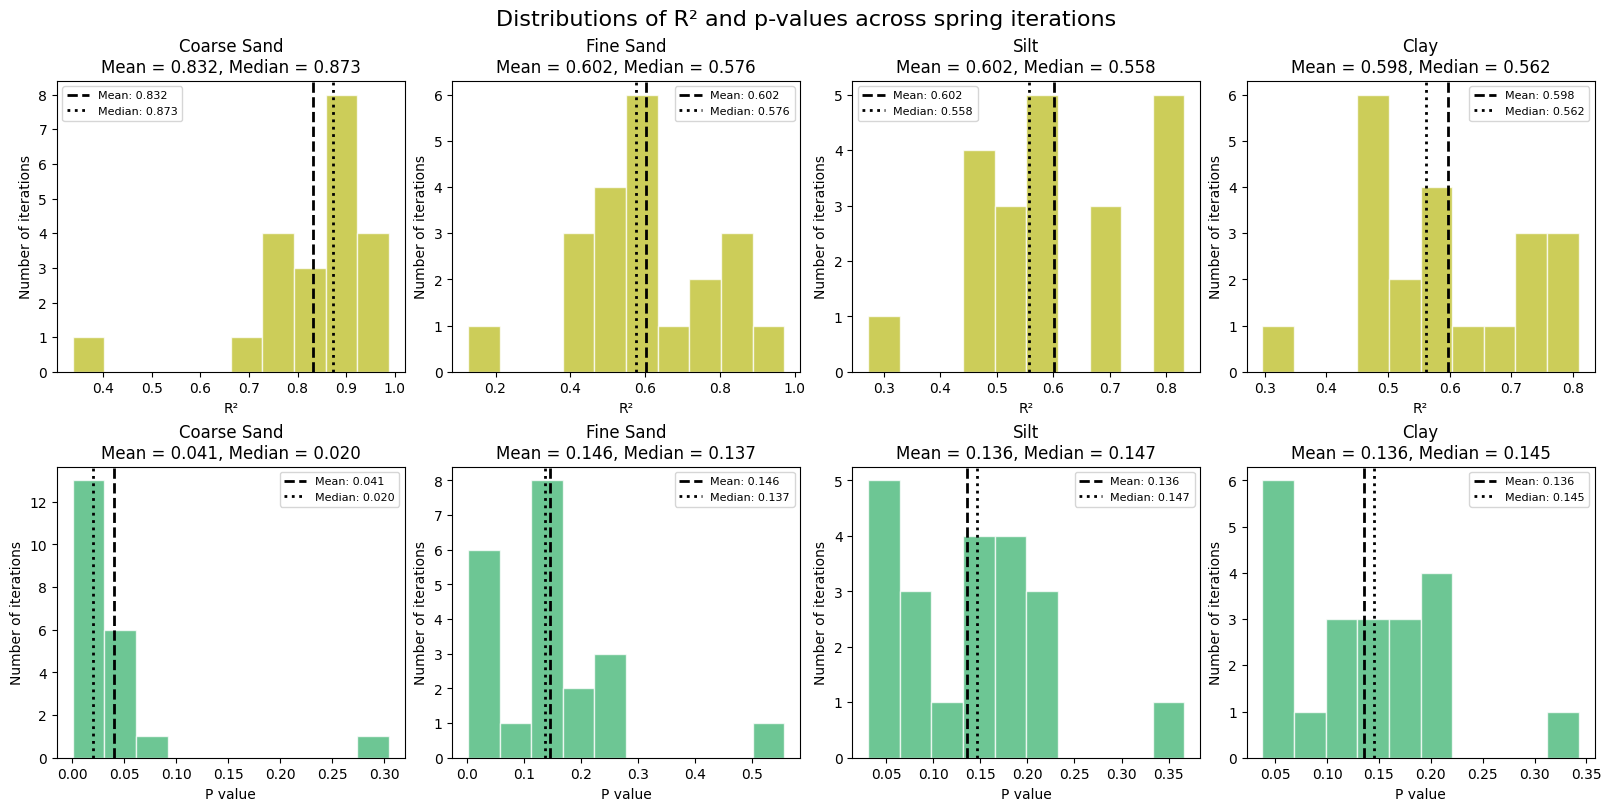

In [6]:
metrics = {
    "r_squared": "R²",
    "p_value": "P value",
}
colors = {
    "r_squared": "tab:olive",
    "p_value": "mediumseagreen",
}

fig, axes = plt.subplots(
    nrows=len(metrics),
    ncols=len(grain_size_columns),
    figsize=(16, 8),
    constrained_layout=True,
)

for row, (metric, label) in enumerate(metrics.items()):
    for column, grain_size in enumerate(grain_size_columns):
        values = spring_iteration_results.loc[
            spring_iteration_results["grain_size"] == grain_size, metric
        ].dropna()
        mean = values.mean()
        median = values.median()
        ax = axes[row, column]

        ax.hist(values, bins=10, color=colors[metric], alpha=0.75, edgecolor="white")
        ax.axvline(mean, color="black", linestyle="--", linewidth=2, label=f"Mean: {mean:.3f}")
        ax.axvline(median, color="black", linestyle=":", linewidth=2, label=f"Median: {median:.3f}")
        ax.set_title(f"{grain_size.replace('_', ' ').title()}\nMean = {mean:.3f}, Median = {median:.3f}")
        ax.set_xlabel(label)
        ax.set_ylabel("Number of iterations")
        ax.legend(fontsize=8)

fig.suptitle("Distributions of R² and p-values across spring iterations", fontsize=16)
plt.show()

In [7]:
comparison_rows = []

for grain_size in grain_size_columns:

    # Get the summer regression
    summer_result = regression_results[
        (regression_results["season"] == "Summer") &
        (regression_results["grain_size"] == grain_size)
    ].iloc[0]

    # Get all spring iterations
    spring_results = spring_iteration_results[
        spring_iteration_results["grain_size"] == grain_size
    ]

    summer_r2 = summer_result["r_squared"]
    summer_p = summer_result["p_value"]

    # Compare every spring iteration against summer
    comparison_rows.append({
        "grain_size": grain_size,
        "summer_r2": summer_r2,
        "spring_r2_mean": spring_results["r_squared"].mean(),
        "spring_r2_median": spring_results["r_squared"].median(),
        "spring_r2_min": spring_results["r_squared"].min(),
        "spring_r2_max": spring_results["r_squared"].max(),

        "spring_subsets_R2_higher": (
            spring_results["r_squared"] > summer_r2
        ).sum(),

        "spring_subsets_R2_higher_pct": (
            spring_results["r_squared"] > summer_r2
        ).mean() * 100,

        "summer_p": summer_p,
        "spring_p_mean": spring_results["p_value"].mean(),
        "spring_p_median": spring_results["p_value"].median(),

        "spring_subsets_p_lower": (
            spring_results["p_value"] < summer_p
        ).sum(),

        "spring_subsets_p_lower_pct": (
            spring_results["p_value"] < summer_p
        ).mean() * 100,
    })

comparison = pd.DataFrame(comparison_rows)

comparison.round(3)

,grain_size,summer_r2,spring_r2_mean,spring_r2_median,spring_r2_min,spring_r2_max,spring_subsets_R2_higher,spring_subsets_R2_higher_pct,summer_p,spring_p_mean,spring_p_median,spring_subsets_p_lower,spring_subsets_p_lower_pct
0,coarse_sand,0.255,0.832,0.873,0.338,0.988,21,100.000,0.385,0.041,0.020,21,100.000
1,fine_sand,0.744,0.602,0.576,0.126,0.972,6,28.571,0.060,0.146,0.137,6,28.571
2,silt,0.404,0.602,0.558,0.273,0.832,20,95.238,0.249,0.136,0.147,20,95.238
3,clay,0.423,0.598,0.562,0.297,0.809,20,95.238,0.234,0.136,0.145,20,95.238
